In [ ]:
%pip install datasets==2.21.0

INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 10.1 MB/s  0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [datasets]
ERROR: pip's dependency resolver does not currently take into ac

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
from datasets import load_dataset

dataset_laptop = load_dataset("jakartaresearch/semeval-absa", name='laptop')
dataset_restaurant = load_dataset("jakartaresearch/semeval-absa", name='restaurant')
dataset_fabsa = load_dataset("jordiclive/FABSA")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


# Deberta for ATSC

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load the ABSA model and tokenizer
model_name = "yangheng/deberta-v3-base-absa-v1.1"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

classifier = pipeline("text-classification", model=model, tokenizer=tokenizer, device='cpu')

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Device set to use cpu


## Evaluate on SemEval on the domain: laptops

  0%|          | 0/800 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative     0.6936    0.9375    0.7973       128
     neutral     0.7760    0.5740    0.6599       169
    positive     0.9147    0.9120    0.9134       341

    accuracy                         0.8276       638
   macro avg     0.7948    0.8078    0.7902       638
weighted avg     0.8336    0.8276    0.8229       638



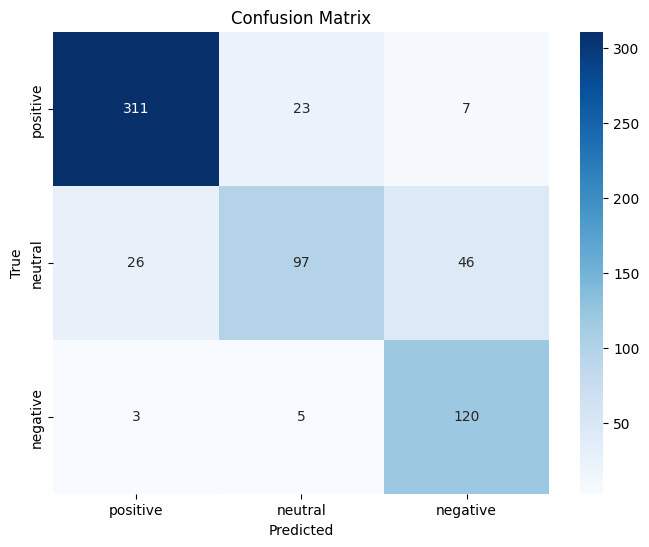

In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = []
predictions = []

POLARITY_SET = set(['positive', 'negative', 'neutral'])

for i, data in enumerate(tqdm(dataset_laptop['validation'])):
    terms = data['aspects']['term']
    polarities = data['aspects']['polarity']

    for term, polarity in zip(terms, polarities):
        if polarity not in POLARITY_SET or term == '':
            continue

        prediction = classifier(data['text'], text_pair=term)
        predictions.append(prediction[0]['label'].lower())
        labels.append(polarity)

print(classification_report(labels, predictions, digits =4))

# Confusion Matrix
conf_matrix = confusion_matrix(labels, predictions, labels=list(POLARITY_SET))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=POLARITY_SET, yticklabels=POLARITY_SET)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


## Evaluate on SemEval on the domain: restaurant

  0%|          | 0/800 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative     0.8525    0.7959    0.8232       196
     neutral     0.5646    0.7806    0.6552       196
    positive     0.9429    0.8626    0.9010       728

    accuracy                         0.8366      1120
   macro avg     0.7867    0.8131    0.7932      1120
weighted avg     0.8609    0.8366    0.8444      1120



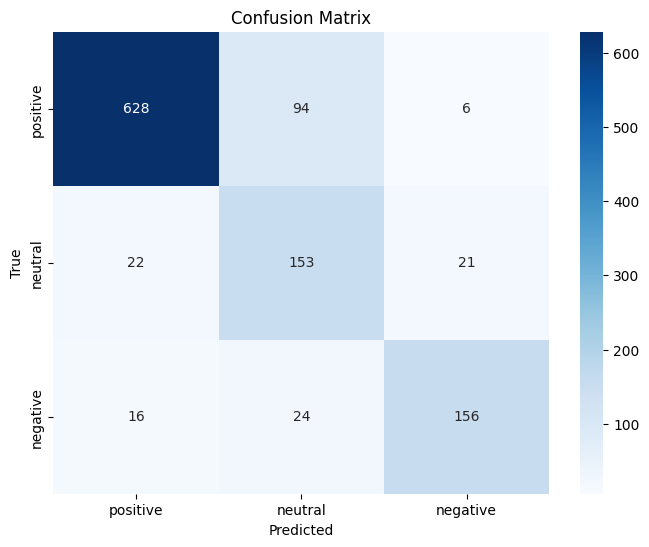

In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = []
predictions = []

POLARITY_SET = set(['positive', 'negative', 'neutral'])

for i, data in enumerate(tqdm(dataset_restaurant['validation'])):
    terms = data['aspects']['term']
    polarities = data['aspects']['polarity']

    for term, polarity in zip(terms, polarities):
        if polarity not in POLARITY_SET or term == '':
            continue

        prediction = classifier(data['text'], text_pair=term)
        predictions.append(prediction[0]['label'].lower())
        labels.append(polarity)

print(classification_report(labels, predictions, digits=4))

# Confusion Matrix
conf_matrix = confusion_matrix(labels, predictions, labels=list(POLARITY_SET))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=POLARITY_SET, yticklabels=POLARITY_SET)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
set(predictions), set(labels), set(predictions) == set(labels)

({'negative', 'neutral', 'positive'},
 {'negative', 'neutral', 'positive'},
 True)

## Evaluate on FABSA

  0%|          | 0/1587 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative     0.9467    0.6741    0.7875       896
     neutral     0.3235    0.7253    0.4475        91
    positive     0.8843    0.9545    0.9181      1825

    accuracy                         0.8578      2812
   macro avg     0.7182    0.7846    0.7177      2812
weighted avg     0.8860    0.8578    0.8612      2812



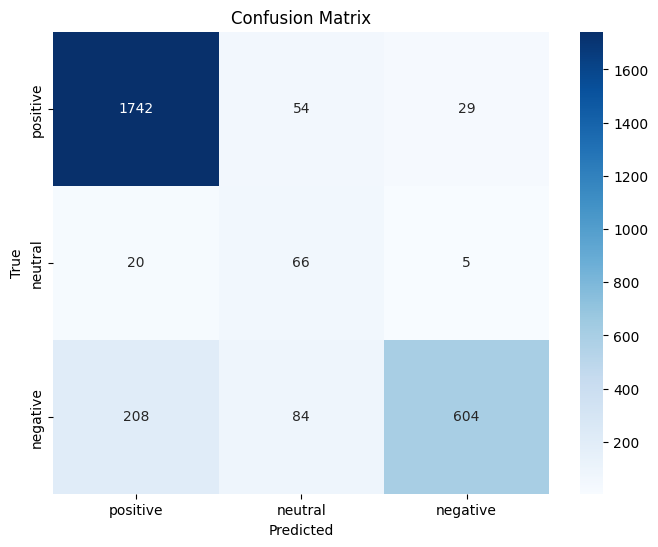

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = []
predictions = []

POLARITY_SET = set(['positive', 'negative', 'neutral'])

for i, data in enumerate(tqdm(dataset_fabsa['test'])):
    for term, polarity in data['labels']:
        if polarity not in POLARITY_SET or term == '':
            continue

        prediction = classifier(data['text'], text_pair=term)
        predictions.append(prediction[0]['label'].lower())
        labels.append(polarity)

print(classification_report(labels, predictions, digits=4))

# Confusion Matrix
conf_matrix = confusion_matrix(labels, predictions, labels=list(POLARITY_SET))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=POLARITY_SET, yticklabels=POLARITY_SET)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# from tqdm.auto import tqdm
# from sklearn.metrics import classification_report, accuracy_score


# labels = []
# predictions = []

# POLARITY_SET = set(['positive', 'negative', 'neutral'])

# for i, data in enumerate(tqdm(dataset_fabsa['test'])):
#     for term, polarity in data['labels']:
#         if polarity not in POLARITY_SET or term == '':
#             continue

#         prediction = classifier(data['text'], text_pair=term.split(': ')[-1])
#         predictions.append(prediction[0]['label'].lower())
#         labels.append(polarity)

# print(classification_report(labels, predictions))
# print(f"accuracy_score = {accuracy_score(labels, predictions)}")

## Sanity Check

In [ ]:
text = """Apart from a few "buffering moments" ordering our shopping has never been easier"""
{
    aspect: classifier(text, text_pair=aspect)[0]['label']
    for aspect in (
        [
            "speed",
            "velocity",
            "waiter",
            "weather",
            "shoes",
            "United States",
            "North Korea",
            "Iran",
            "United Kingdom",
        ]
    )
}

{'speed': 'Positive',
 'velocity': 'Positive',
 'waiter': 'Positive',
 'weather': 'Positive',
 'shoes': 'Positive',
 'United States': 'Positive',
 'North Korea': 'Negative',
 'Iran': 'Positive',
 'United Kingdom': 'Positive'}

# InstructABSA for ATSC
It uses a trained Tk-base-pos-def model

In [ ]:
!pip install -U "transformers==4.57.1" "tokenizers>=0.22.0,<0.23.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 78.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 110.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 20.6 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.21.0
    Uninstalling transformers-5.21.0:
      Successfully uninstalled transformers-5.21.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency con

In [ ]:
# Use a pipeline as a high-level helper
from transformers import pipeline

classifier = pipeline("text2text-generation", model="kevinscaria/atsc_tk-instruct-base-def-pos-neg-neut-combined", device='cpu')

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use cpu


In [ ]:
bos_instruction = """Definition: The output will be 'positive' if the aspect identified in the sentence contains a positive sentiment. If the sentiment of the identified aspect in the input is negative the answer will be 'negative'.
        Otherwise, the output should be 'neutral'. For aspects which are classified as noaspectterm, the sentiment is none.
        Positive example 1-
        input: With the great variety on the menu , I eat here often and never get bored. The aspect is menu.
        output: positive
        Positive example 2-
        input: Great food, good size menu, great service and an unpretensious setting. The aspect is food.
        output: positive
        Negative example 1-
        input: They did not have mayonnaise, forgot our toast, left out ingredients (ie cheese in an omelet), below hot temperatures and the bacon was so over cooked it crumbled on the plate when you touched it. The aspect is toast.
        output: negative
        Negative example 2-
        input: The seats are uncomfortable if you are sitting against the wall on wooden benches. The aspect is seats.
        output: negative
        Neutral example 1-
        input: I asked for seltzer with lime, no ice. The aspect is seltzer with lime.
        output: neutral
        Neutral example 2-
        input: They wouldnt even let me finish my glass of wine before offering another. The aspect is glass of wine.
        output: neutral
        Now complete the following example-
        input: """

sep_instruction = ' The aspect is '
eos_instruction = '.\noutput:'

text = "Boot time is super fast, around anywhere from 35 seconds to 1 minute."
aspect = "Boot time"

input_text = bos_instruction + text + sep_instruction + aspect + eos_instruction

classifier(input_text, max_new_tokens=1)[0]['generated_text']

'positive'

## Sanity Check

In [ ]:
text = "Apart from a few \"buffering moments\" ordering our shopping has never been easier"

{
    aspect: classifier(bos_instruction + text + sep_instruction + aspect + eos_instruction, max_new_tokens=1)[0]['generated_text']
    for aspect in (
        [
            "speed",
            "velocity",
            "waiter",
            "weather",
            "shoes",
            "North Korea",
            "United States",
            "Iran"
        ]
    )
}

{'speed': 'positive',
 'velocity': 'positive',
 'waiter': 'positive',
 'weather': 'negative',
 'shoes': 'positive',
 'North Korea': 'negative',
 'United States': 'neutral',
 'Iran': 'positive'}

## Evaluate on SemEval on the domain: laptop

  0%|          | 0/800 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative     0.6514    0.8906    0.7525       128
     neutral     0.8723    0.4852    0.6236       169
    positive     0.8699    0.9413    0.9042       341

    accuracy                         0.8103       638
   macro avg     0.7979    0.7724    0.7601       638
weighted avg     0.8267    0.8103    0.7994       638



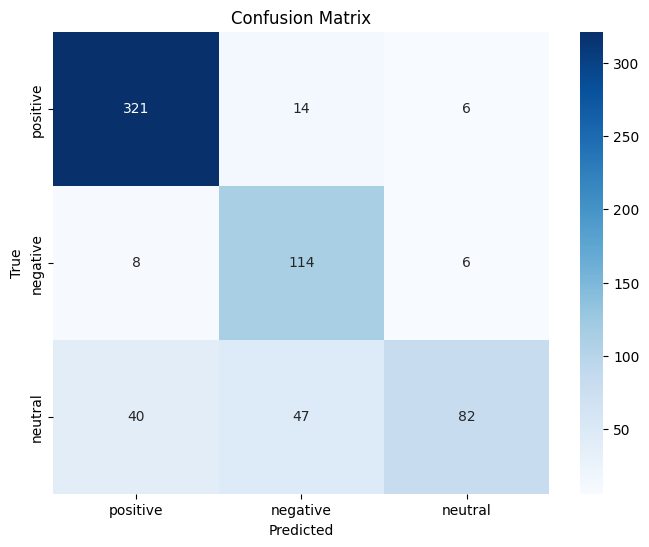

In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = []
predictions = []

for i, data in enumerate(tqdm(dataset_laptop['validation'])):
    for term, polarity in zip(data['aspects']['term'], data['aspects']['polarity']):
        if polarity == 'conflict':
            continue
        if term == '':
            pass
            # predictions.append('')
        else:
            aspect = term
            text = data['text']
            input_text = bos_instruction + text + sep_instruction + aspect + eos_instruction
            prediction = classifier(input_text, max_new_tokens=1)
            predictions.append(prediction[0]['generated_text'].lower())
            labels.append(polarity)

print(classification_report(labels, predictions, digits=4))

# Confusion Matrix
unique_labels = list(set(labels + predictions))  # Ensure labels cover both true and predicted
conf_matrix = confusion_matrix(labels, predictions, labels=unique_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=unique_labels, yticklabels=unique_labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


## Evaluate on SemEval on the domain: restaurant

  0%|          | 0/800 [00:00<?, ?it/s]

              precision    recall  f1-score   support

    negative     0.8000    0.8776    0.8370       196
     neutral     0.7658    0.4337    0.5537       196
    positive     0.8904    0.9712    0.9290       728

    accuracy                         0.8607      1120
   macro avg     0.8187    0.7608    0.7733      1120
weighted avg     0.8528    0.8607    0.8473      1120



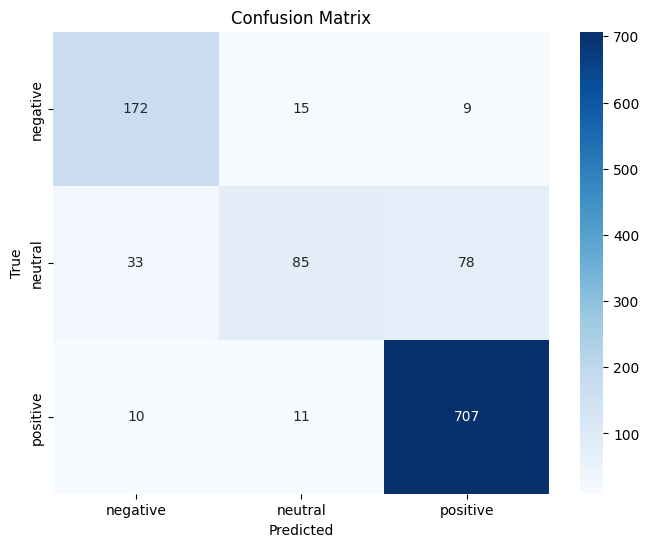

In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = []
predictions = []

for i, data in enumerate(tqdm(dataset_restaurant['validation'])):
    for term, polarity in zip(data['aspects']['term'], data['aspects']['polarity']):
        if polarity == 'conflict':
            continue
        if term == '':
            pass
            # predictions.append('')
        else:
            aspect = term
            text = data['text']
            input_text = bos_instruction + text + sep_instruction + aspect + eos_instruction
            prediction = classifier(input_text, max_new_tokens=1)
            predictions.append(prediction[0]['generated_text'].lower())
            labels.append(polarity)

print(classification_report(labels, predictions, digits=4))

# Confusion Matrix
unique_labels = list(set(labels + predictions))  # Ensure labels cover both true and predicted
conf_matrix = confusion_matrix(labels, predictions, labels=unique_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=unique_labels, yticklabels=unique_labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
set(predictions), set(labels), set(predictions) == set(labels)

({'negative', 'neutral', 'positive'},
 {'negative', 'neutral', 'positive'},
 True)

## Evaluate on FABSA

  0%|          | 0/1587 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (614 > 512). Running this sequence through the model will result in indexing errors


              precision    recall  f1-score   support

    negative     0.9292    0.1172    0.2081       896
     neutral     0.0781    0.9231    0.1441        91
    positive     0.9550    0.8499    0.8994      1825

    accuracy                         0.6188      2812
   macro avg     0.6541    0.6300    0.4172      2812
weighted avg     0.9184    0.6188    0.6547      2812



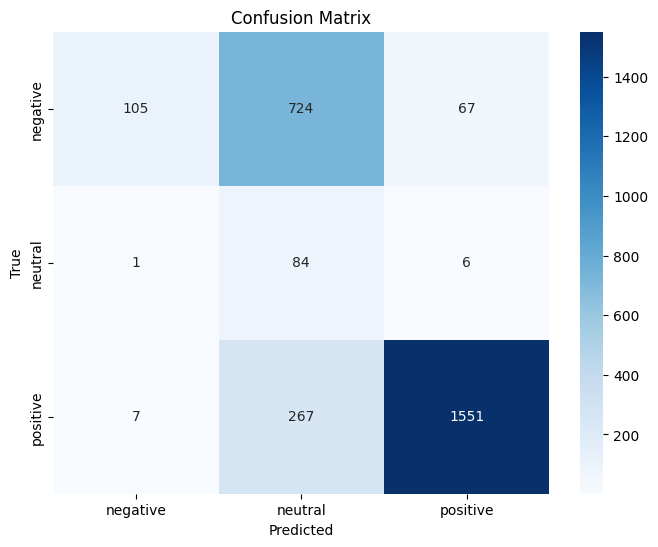

In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = []
predictions = []

POLARITY_SET = set(['positive', 'negative', 'neutral'])

for i, data in enumerate(tqdm(dataset_fabsa['test'])):
    for term, polarity in data['labels']:
        if polarity not in POLARITY_SET or term == "":
            continue
        input_text = (
            bos_instruction
            + data['text']
            + sep_instruction
            + aspect.split(": ")[-1]
            + eos_instruction
        )

        prediction = classifier(input_text, max_new_tokens=1)
        predictions.append(prediction[0]['generated_text'].lower())
        labels.append(polarity)

print(classification_report(labels, predictions, digits=4))

# Confusion Matrix
unique_labels = list(set(labels + predictions))  # Ensure labels cover both true and predicted
conf_matrix = confusion_matrix(labels, predictions, labels=unique_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=unique_labels, yticklabels=unique_labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# from tqdm.auto import tqdm
# from sklearn.metrics import classification_report, accuracy_score


# labels = []
# predictions = []

# POLARITY_SET = set(['positive', 'negative', 'neutral'])

# for i, data in enumerate(tqdm(dataset_fabsa['test'])):
#     for term, polarity in data['labels']:
#         if polarity not in POLARITY_SET or term == '':
#             continue

#         input_text = (
#             bos_instruction
#             + data['text']
#             + sep_instruction
#             + aspect.split(": ")[-1]
#             + eos_instruction
#         )
#         prediction = classifier(input_text, max_new_tokens=1)
#         predictions.append(prediction[0]['generated_text'].lower())
#         labels.append(polarity)

# print(classification_report(labels, predictions))
# print(f"accuracy_score = {accuracy_score(labels, predictions)}")

# PyABSA

In [ ]:
%pip install -qU pyabsa

In [ ]:
from pyabsa import AspectTermExtraction as ATEPC


aspect_extractor = ATEPC.AspectExtractor('multilingual', auto_device=True)

In [ ]:
instances = [
    # "The battery life of this phone is incredible, but the screen cracks too easily and the camera quality is disappointing.",
    # "While the hotel's location is perfect and the breakfast delicious, the room was noisy and the staff unhelpful.",
    "Apart from a few \"buffering moments\" ordering our shopping has never been easier"
]

# instance inference
atepc_result = aspect_extractor.predict(instances,
    save_result=True,
    print_result=True,  # print the result
    ignore_error=True,  # ignore the error when the model cannot predict the input
)

In [ ]:
from pprint import pprint

pprint(atepc_result, width=400)